<p align="center">
  <img src="chart_zoom.jpg" alt="chart_zoom">
</p>

Fraud doesn’t just cost money—it costs trust. As a key member of a financial compliance team, your mission is to uncover suspicious transactions that might otherwise slip through the cracks. With the stakes this high, your insights could be the difference between stopping fraud in its tracks or letting it go unnoticed.

In this project, you'll harness the power of IForest from pyod.models to detect anomalies in banking data. Your challenge: flag unusual transactions, summarize your findings, and deliver actionable insights that ensure trust, security, and efficiency in financial operations.

## Hints and Notes

- Ensure there are no missing values in the output DataFrame.
- Be sure to label the axes and legend clearly on the histogram to make the anomalies easily identifiable.

## The Data

You will work with a dataset containing information about financial transactions. Below is a summary of the key columns provided:

| **Column**              | **Description**                                                                                   |
|--------------------------|---------------------------------------------------------------------------------------------------|
| `TransactionID`          | A unique identifier for each transaction.                                                       |
| `TransactionAmount`      | The amount of money involved in the transaction (in USD).                                        |
| `TransactionDuration`    | Duration of the transaction (in seconds).                                                       |
| `AccountBalance`         | The balance of the account after the transaction was processed (in USD).                        |



In [1]:
# Re-run this cell
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset
transactions = pd.read_csv("transactions.csv")

# Isolate key columns
columns_to_display = ["TransactionID", "TransactionAmount", "TransactionDuration", "AccountBalance"]
transactions = transactions[columns_to_display]

# Display the first rows of the table
transactions.head()

,TransactionID,TransactionAmount,TransactionDuration,AccountBalance
0,TX000001,14.09,81,5112.21
1,TX000002,376.24,141,13758.91
2,TX000003,126.29,56,1122.35
3,TX000004,184.50,25,8569.06
4,TX000005,13.45,198,7429.40


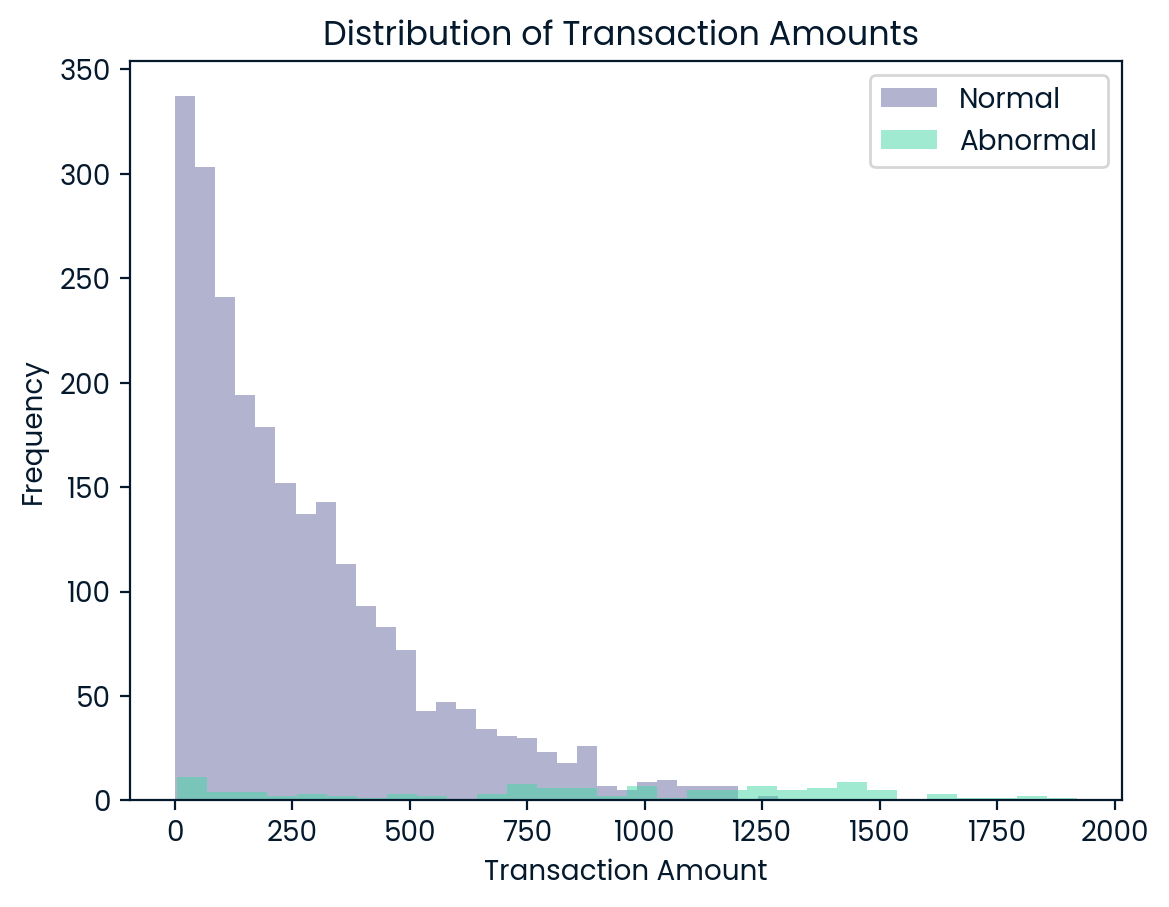

,TransactionID,TransactionAmount,TransactionDuration,AccountBalance,Anomaly_Score,Anomaly
0,TX000001,14.09,81,5112.21,0.104621,0
1,TX000002,376.24,141,13758.91,0.389899,0
2,TX000003,126.29,56,1122.35,0.045974,0
3,TX000004,184.50,25,8569.06,0.199612,0
4,TX000005,13.45,198,7429.40,0.228275,0
...,...,...,...,...,...,...
2507,TX002508,856.21,109,12690.79,0.529730,0
2508,TX002509,251.54,177,254.75,0.196249,0
2509,TX002510,28.63,146,3382.91,0.103170,0
2510,TX002511,185.97,19,1776.91,0.203130,0


In [2]:
# Start coding here
# Use as many cells as you need

# Computing Anomaly scores
from pyod.models.iforest import IForest

# Selecting features
features= transactions[["TransactionAmount", "TransactionDuration", "AccountBalance"]]

# Tuning the model
contamination=0.05

# Generating Scores
model = IForest(contamination=contamination)
model.fit(features)
probs = model.predict_proba(features)

outlier_probs = probs[:, 1]

transactions['Anomaly_Score'] = outlier_probs
#####################
# Flagging transactions as anomalies

# Defining anomalies
threshold=0.55

# Adding a column to flag anomalous transactions
transactions['Anomaly'] = transactions['Anomaly_Score'] >= threshold
transactions['Anomaly'] = transactions['Anomaly'].replace({True: 1, False: 0})

#####################
# Create a summary of anomalous transactions

# Selecting relevant columns and save summary
anomalies_summary = transactions[transactions['Anomaly'] == 1][['TransactionID','TransactionAmount','TransactionDuration','AccountBalance']]

#####################
# Visualise the result with a histogram
# Prepare data
normal_transactions = transactions[transactions['Anomaly'] == 0]
anomalies_transactions = transactions[transactions['Anomaly'] == 1]

# Plot histogram
plt.hist(normal_transactions['TransactionAmount'],
         bins=30,
         alpha=0.5,
         label='Normal')

plt.hist(anomalies_transactions['TransactionAmount'],
         bins=30,
         alpha=0.5,
         label='Abnormal')

plt.legend(loc='upper right')
plt.title('Distribution of Transaction Amounts ')
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.savefig('anomalies_histogram.png')
plt.show()
transactions

,TransactionID,AccountID,TransactionAmount,TransactionDate,TransactionType,Location,DeviceID,IP Address,MerchantID,Channel,CustomerAge,CustomerOccupation,TransactionDuration,LoginAttempts,AccountBalance,PreviousTransactionDate,Anomaly_Score,Anomaly
0,TX000001,AC00128,14.09,2023-04-11 16:29:14,Debit,San Diego,D000380,162.198.218.92,M015,ATM,70,Doctor,81,1,5112.21,2024-11-04 08:08:08,-0.127230,0
1,TX000002,AC00455,376.24,2023-06-27 16:44:19,Debit,Houston,D000051,13.149.61.4,M052,ATM,68,Doctor,141,1,13758.91,2024-11-04 08:09:35,-0.043850,0
2,TX000003,AC00019,126.29,2023-07-10 18:16:08,Debit,Mesa,D000235,215.97.143.157,M009,Online,19,Student,56,1,1122.35,2024-11-04 08:07:04,-0.150263,0
3,TX000004,AC00070,184.50,2023-05-05 16:32:11,Debit,Raleigh,D000187,200.13.225.150,M002,Online,26,Student,25,1,8569.06,2024-11-04 08:09:06,-0.105860,0
4,TX000005,AC00411,13.45,2023-10-16 17:51:24,Credit,Atlanta,D000308,65.164.3.100,M091,Online,26,Student,198,1,7429.40,2024-11-04 08:06:39,-0.096070,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2507,TX002508,AC00297,856.21,2023-04-26 17:09:36,Credit,Colorado Springs,D000625,21.157.41.17,M072,Branch,33,Doctor,109,1,12690.79,2024-11-04 08:11:29,-0.010342,0
2508,TX002509,AC00322,251.54,2023-03-22 17:36:48,Debit,Tucson,D000410,49.174.157.140,M029,Branch,48,Doctor,177,1,254.75,2024-11-04 08:11:42,-0.107260,0
2509,TX002510,AC00095,28.63,2023-08-21 17:08:50,Debit,San Diego,D000095,58.1.27.124,M087,Branch,56,Retired,146,1,3382.91,2024-11-04 08:08:39,-0.141030,0
2510,TX002511,AC00118,185.97,2023-02-24 16:24:46,Debit,Denver,D000634,21.190.11.223,M041,Online,23,Student,19,1,1776.91,2024-11-04 08:12:22,-0.114754,0


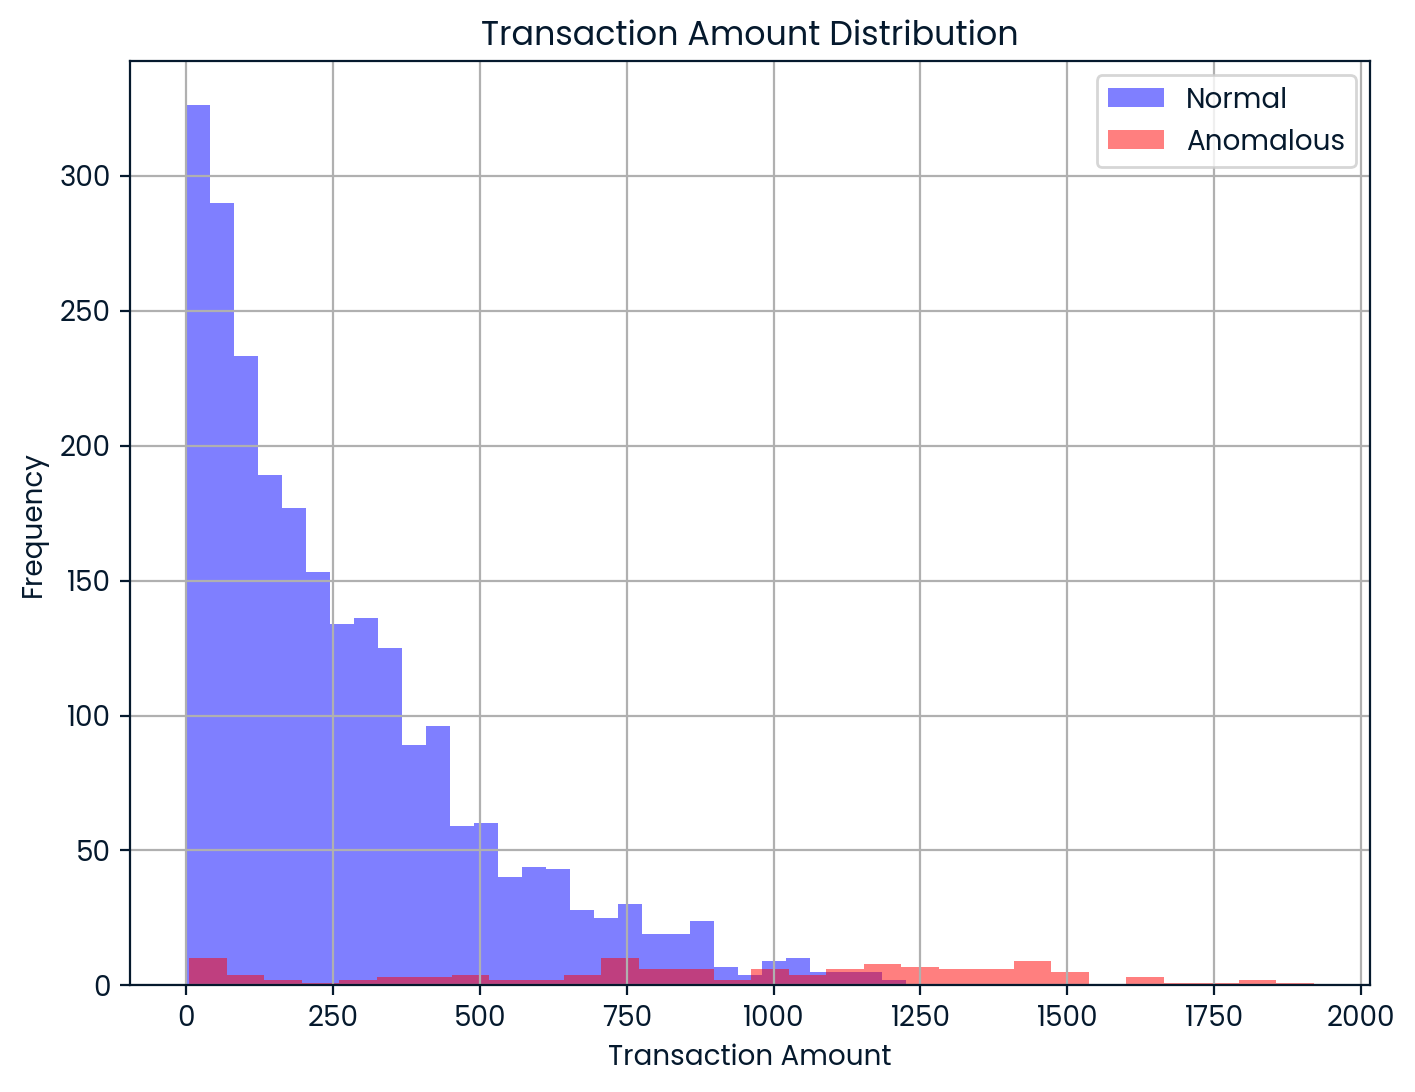

In [3]:
# Import required libraries
import pandas as pd
from pyod.models.iforest import IForest
import matplotlib.pyplot as plt

# Load the dataset
transactions = pd.read_csv("transactions.csv")

# Select numerical features for anomaly detection
features = transactions[["TransactionAmount", "TransactionDuration", "AccountBalance"]]

# Train an IForest model with n_estimators parameter
model = IForest(n_estimators=100, contamination=0.05, random_state=42)
model.fit(features)

# Add the anomaly scores to the dataset
transactions["Anomaly_Score"] = model.decision_function(features)

# Flag transactions as anomalies based on the model's prediction
transactions["Anomaly"] = (model.predict(features) == 1).astype(int)  # Convert boolean to integer


# Create a summary of anomalous transactions
anomalies_summary = transactions.loc[transactions["Anomaly"] == 1, ["TransactionID", "TransactionAmount", "TransactionDuration", "AccountBalance"]]


# Plot the distribution of TransactionAmount for normal and anomalous transactions
plt.figure(figsize=(8, 6))
transactions[transactions["Anomaly"] == False]["TransactionAmount"].hist(bins=30, alpha=0.5, label="Normal", color="blue")
transactions[transactions["Anomaly"] == True]["TransactionAmount"].hist(bins=30, alpha=0.5, label="Anomalous", color="red")
plt.title("Transaction Amount Distribution")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.legend()
plt.savefig("anomalies_histogram.png")

transactions

In [6]:
transactions["Anomaly"].value_counts()
len(transactions["Anomaly"])
126/2512

0.05015923566878981